# IRWA Final Project — Part 1: Text Processing and Exploratory Data Analysis

**Corpus:** `data/fashion_products_dataset.json` (Flipkart fashion products)
**Evaluation hint:** `data/validation_labels.csv` (2 queries, 20 labelled products each)

Structure of this notebook:
1. Setup and data loading
2. **Data preparation** (statement points 1–4)
3. **Exploratory data analysis**
4. Save the processed corpus for Part 2

The pre-processing functions are defined in this notebook. Running it writes the figures to `project_progress/part_1/figures/` so they can be pasted into the report.


## 1. Setup and data loading

In [1]:
import json, re, collections
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the repository root (the folder that contains `myapp/` and `data/`)
ROOT = Path.cwd()
while not (ROOT / "myapp").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "data"
FIG = ROOT / "project_progress" / "part_1" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

import nltk
nltk.download("stopwords", quiet=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

print("Repository root:", ROOT)


Repository root: irwa-search-engine


In [ ]:
# Pre-processing for this notebook: text fields, brands, product details and numeric metadata.
from __future__ import annotations

import html
import re
import unicodedata
from typing import Any, Dict, Iterable, List, Optional
from urllib.parse import urlparse

import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

# ---------------------------------------------------------------------------
# Resources
# ---------------------------------------------------------------------------

def _load_stopwords() -> set:
    """Load the NLTK English stop-word list, downloading it on first use."""
    try:
        return set(stopwords.words("english"))
    except LookupError:
        import nltk
        nltk.download("stopwords", quiet=True)
        return set(stopwords.words("english"))


STOP_WORDS: set = _load_stopwords()
STEMMER = SnowballStemmer("english")

# A token is either a word (letters/digits) or a run of punctuation/symbols.
# Keeping those two kinds apart is what makes "remove punctuation" its own step.
_TOKEN_RE = re.compile(r"[a-z0-9]+|[^a-z0-9\s]+")
_WORD_RE = re.compile(r"[a-z0-9]+")
# Hyphen or apostrophe *inside* a word: "t-shirt" -> "tshirt", "men's" -> "mens".
_INNER_JOIN_RE = re.compile(r"(?<=[a-z0-9])[-'’](?=[a-z0-9])")

# product_details keys that are identifiers or logistics, not product descriptors.
# They add noise terms ("1005combo2", "india", "machine wash") that never match a fashion query.
DETAILS_EXCLUDED_KEYS = {
    "style code", "model name", "fabric care", "care instructions", "sales package",
    "pack of", "number of contents in sales package", "size", "country of origin",
    "domestic warranty", "reversible", "",
}


# ---------------------------------------------------------------------------
# Text fields
# ---------------------------------------------------------------------------

def normalize_text(text: Optional[str]) -> str:
    """
    Normalise raw text before tokenisation.

    - HTML entities are decoded ("&amp;" -> "&").
    - Unicode is normalised (NFKD) and accents are dropped, so "café" == "cafe".
    - Non-breaking spaces and other odd whitespace become plain spaces.
    - Everything is lower-cased.
    - Hyphens/apostrophes inside words are removed, so "T-Shirt" and "tshirt" become the same term.
    """
    if not text:
        return ""
    text = html.unescape(str(text))
    text = unicodedata.normalize("NFKD", text)
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    text = text.lower().replace("\xa0", " ")
    text = _INNER_JOIN_RE.sub("", text)
    return text


def tokenize(text: str) -> List[str]:
    """Split text into tokens. Punctuation stays as its own tokens ("," "!" "..." )."""
    return _TOKEN_RE.findall(text)


def remove_punctuation(tokens: List[str]) -> List[str]:
    """Drop tokens that are only punctuation or symbols. Word tokens are unchanged."""
    return [tok for tok in tokens if _WORD_RE.fullmatch(tok)]


def remove_stop_words(tokens: List[str]) -> List[str]:
    """Drop tokens that appear in the NLTK English stop-word list."""
    return [tok for tok in tokens if tok not in STOP_WORDS]


def stem_tokens(tokens: List[str]) -> List[str]:
    """Apply the Snowball (Porter2) stemmer to every token."""
    return [STEMMER.stem(tok) for tok in tokens]


def build_terms(text: Optional[str], stem: bool = True, keep_numbers: bool = False) -> List[str]:
    """
    Turn one text field (or a query) into a list of index terms.

    After normalisation, the four required steps run one after another:
    tokenization, remove punctuation, remove stop words, stemming.
    Pure numbers and 1-character tokens are dropped before stemming.

    :param text: raw text (title, description, query, ...)
    :param stem: apply the Snowball (Porter2) stemmer
    :param keep_numbers: keep purely numeric tokens such as "100" or "32"
    :return: list of terms, in original order (duplicates kept, needed for tf later)
    """
    normalised = normalize_text(text)

    # 1. Tokenization
    tokens = tokenize(normalised)

    # 2. Remove punctuation marks
    tokens = remove_punctuation(tokens)

    # 3. Remove stop words
    tokens = remove_stop_words(tokens)
    if not keep_numbers:
        tokens = [tok for tok in tokens if not tok.isdigit()]
    tokens = [tok for tok in tokens if len(tok) >= 2]

    # 4. Stemming
    if stem:
        tokens = stem_tokens(tokens)
    return tokens


def normalize_entity(text: Optional[str]) -> str:
    """
    Normalise a brand or seller name into ONE exact-match token.

    Names are proper nouns: stemming or splitting them would create false matches
    ("Levi's" vs "level"), so we only lower-case and remove spaces/punctuation:
    "Shyam Enterprises" -> "shyamenterprises", "Levi's" -> "levis".
    """
    return "".join(remove_punctuation(tokenize(normalize_text(text))))


def repair_brand(brand: Optional[str], url: Optional[str]) -> str:
    """
    Recover the full brand name, which is truncated in the dataset ("REEB", "Pu", "ECKO Unl").

    The product URL starts with a slug that begins with the full brand name
    (".../reebok-full-sleeve-solid-men-sweatshirt/p/..."). We join slug words one by one
    until they start with the truncated brand: "reeb" -> "reebok", "eckounl" -> "ecko unltd".
    If no prefix matches (or there is no brand), the original value is returned unchanged.
    """
    if not brand:
        return ""
    b = "".join(remove_punctuation(tokenize(normalize_text(brand))))
    if not b or not url:
        return brand
    path = urlparse(url).path.strip("/")
    slug_words = path.split("/")[0].split("-") if path else []
    acc = ""
    for i, word in enumerate(slug_words[:6]):
        acc += word
        if acc.startswith(b):
            return " ".join(slug_words[: i + 1])
    return brand


# ---------------------------------------------------------------------------
# product_details
# ---------------------------------------------------------------------------

def flatten_product_details(details: Any) -> Dict[str, str]:
    """Convert the raw list of one-key dicts into a single dict {attribute: value}."""
    flat: Dict[str, str] = {}
    if isinstance(details, list):
        for item in details:
            if isinstance(item, dict):
                for k, v in item.items():
                    flat[str(k).strip()] = str(v).strip()
    elif isinstance(details, dict):
        flat = {str(k).strip(): str(v).strip() for k, v in details.items()}
    return flat


def details_to_text(details: Dict[str, str]) -> str:
    """
    Keep only descriptive attributes (fabric, pattern, fit, sleeve, colour, ideal for...)
    and return them as plain text ready for build_terms.

    Yes/No attributes become the attribute name when "Yes" ("Hooded: Yes" -> "hooded")
    and are dropped when "No", because a bare "yes" carries no meaning.
    """
    parts = []
    for key, value in details.items():
        k = key.lower().strip()
        if k in DETAILS_EXCLUDED_KEYS:
            continue
        v = value.lower().strip()
        if v in {"yes", "no", "na", "n/a", "none", ""}:
            if v == "yes":
                parts.append(key)
            continue
        parts.append(value)
    return " ".join(parts)


# ---------------------------------------------------------------------------
# Numeric / boolean fields (kept as typed metadata, NOT as index terms)
# ---------------------------------------------------------------------------

def parse_price(value: Any) -> Optional[float]:
    """'2,999' -> 2999.0 ; '' / None / garbage -> None."""
    if value is None:
        return None
    if isinstance(value, (int, float)):
        return float(value)
    v = str(value).replace(",", "").strip()
    try:
        return float(v) if v else None
    except ValueError:
        return None


def parse_discount(value: Any) -> Optional[float]:
    """'69% off' -> 69.0 (percentage) ; '' / None -> None."""
    if value is None:
        return None
    if isinstance(value, (int, float)):
        return float(value)
    m = re.search(r"(\d+(?:\.\d+)?)", str(value).replace(",", ""))
    return float(m.group(1)) if m else None


def parse_rating(value: Any) -> Optional[float]:
    """'3.9' -> 3.9 ; '' / None -> None. Ratings outside [0, 5] are treated as missing."""
    r = parse_price(value)
    return r if r is not None and 0 <= r <= 5 else None


# ---------------------------------------------------------------------------
# Documents
# ---------------------------------------------------------------------------

def preprocess_document(rec: Dict[str, Any]) -> Dict[str, Any]:
    """
    Process one raw product record.

    Output keeps:
      * the original display fields required by the statement (pid, title, description,
        brand, category, sub_category, product_details, seller, out_of_stock, prices,
        discount, average_rating, url) - untouched, to show them in results;
      * one list of terms per searchable field (field-based index for Parts 2-3);
      * all_terms: the concatenation of every field (single-field baseline index);
      * typed numeric metadata for filtering / ranking.
    """
    details = flatten_product_details(rec.get("product_details"))
    brand_full = repair_brand(rec.get("brand"), rec.get("url"))
    brand_tok = normalize_entity(brand_full)
    seller_tok = normalize_entity(rec.get("seller"))

    title_terms = build_terms(rec.get("title"))
    description_terms = build_terms(rec.get("description"))
    category_terms = build_terms(rec.get("category"))
    sub_category_terms = build_terms(rec.get("sub_category"))
    details_terms = build_terms(details_to_text(details))
    brand_terms = [brand_tok] if brand_tok else []

    return {
        # identifier + display fields (unchanged)
        "pid": rec.get("pid"),
        "title": rec.get("title"),
        "description": rec.get("description") or "",
        "brand": rec.get("brand") or "",
        "brand_full": brand_full,          # repaired name (see repair_brand)
        "category": rec.get("category") or "",
        "sub_category": rec.get("sub_category") or "",
        "product_details": details,
        "seller": rec.get("seller") or "",
        "url": rec.get("url"),
        # searchable fields
        "title_terms": title_terms,
        "description_terms": description_terms,
        "brand_terms": brand_terms,
        "category_terms": category_terms,
        "sub_category_terms": sub_category_terms,
        "details_terms": details_terms,
        "seller_token": seller_tok,  # stored, not merged into all_terms (see notebook)
        "all_terms": (title_terms + description_terms + brand_terms
                      + category_terms + sub_category_terms + details_terms),
        # typed metadata
        "out_of_stock": bool(rec.get("out_of_stock", False)),
        "selling_price": parse_price(rec.get("selling_price")),
        "actual_price": parse_price(rec.get("actual_price")),
        "discount": parse_discount(rec.get("discount")),
        "average_rating": parse_rating(rec.get("average_rating")),
    }


def preprocess_corpus(records: Iterable[Dict[str, Any]]) -> pd.DataFrame:
    """Process every record and return a DataFrame indexed by pid."""
    df = pd.DataFrame([preprocess_document(r) for r in records])
    return df.set_index("pid", drop=False)


def preprocess_query(query: str) -> List[str]:
    """Process a query with exactly the same pipeline as document text fields."""
    return build_terms(query)


In [2]:
with open(DATA / "fashion_products_dataset.json", encoding="utf-8") as f:
    raw = json.load(f)
raw_df = pd.DataFrame(raw)
labels = pd.read_csv(DATA / "validation_labels.csv")

print(f"{len(raw_df):,} products, {raw_df.shape[1]} fields")
print("Unique pids:", raw_df['pid'].nunique())
raw_df.head(3)

28,080 products, 17 fields
Unique pids: 28080


,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,1612987911000,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed c...,66% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...


## 2. Data preparation

### 2.1 Text pipeline for `title` and `description` (statement point 1)

`build_terms(text)` applies, in order:

| Step | What it does | Why |
|---|---|---|
| Normalisation | decode HTML entities, strip accents, lower-case, replace non-breaking spaces | the same word must always produce the same term |
| Join inner hyphens/apostrophes | `T-Shirt` → `tshirt`, `men's` → `mens` | otherwise "t-shirt" splits into a useless "t" + "shirt" |
| Tokenisation | words and punctuation become separate tokens | `cotton,` → `cotton` + `,` |
| Remove punctuation | drop tokens that are only symbols | `,` `!` `%` never enter the index |
| Stop words | NLTK English list (198 words) | very frequent words with no discriminative power |
| Pure numbers and 1-char tokens | dropped | sizes, pack counts, "100%"… are noise for text matching |
| Stemming | Snowball (Porter2) | `printed`→`print`, `jeans`→`jean`, `sleeves`→`sleev` |

Note: **`men` and `women` are not stop words** in the NLTK list and are kept. They are decisive in both validation queries.

In [3]:
example = raw[0]
print("TITLE      :", example["title"])
print("  terms    :", build_terms(example["title"]))
print("DESCRIPTION:", example["description"][:160], "...")
print("  terms    :", build_terms(example["description"])[:25])
print()
for q in ["women full sleeve sweatshirt cotton", "men slim jeans blue"]:
    print(f"Query {q!r:40} ->", preprocess_query(q))

TITLE      : Solid Women Multicolor Track Pants
  terms    : ['solid', 'women', 'multicolor', 'track', 'pant']
DESCRIPTION: Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year rou ...
  terms    : ['yorker', 'trackpant', 'made', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friend', 'fabric', 'itchfre', 'waistband', 'great', 'year', 'round', 'use', 'proud', 'made', 'india']

Query 'women full sleeve sweatshirt cotton'    -> ['women', 'full', 'sleev', 'sweatshirt', 'cotton']
Query 'men slim jeans blue'                    -> ['men', 'slim', 'jean', 'blue']


In [4]:
# Effect of each extra normalisation step on a few tricky strings
for s in ["Men's Slim-Fit T-Shirt (Pack of 2)", "100% Cotton, itch-free waistband!", "nu-Lite Satin Tie\xa0\xa0(Pink)"]:
    print(f"{s!r:45} -> {build_terms(s)}")

"Men's Slim-Fit T-Shirt (Pack of 2)"          -> ['men', 'slimfit', 'tshirt', 'pack']
'100% Cotton, itch-free waistband!'           -> ['cotton', 'itchfre', 'waistband']
'nu-Lite Satin Tie\xa0\xa0(Pink)'             -> ['nulit', 'satin', 'tie', 'pink']


### 2.2 Fields kept for the output (statement point 2)

Future result lists must show: `pid, title, description, brand, category, sub_category, product_details, seller,
out_of_stock, selling_price, discount, actual_price, average_rating, url`.
The processed corpus keeps all of them **unchanged** (for display) next to the processed terms (for search).
`pid` is never modified, because evaluation uses it.

### 2.3 How to handle `category`, `sub_category`, `brand`, `product_details`, `seller` (statement point 3)

Before deciding, we look at how *distinctive* each field is (number of distinct values, coverage)
and at what separates relevant from non-relevant products in `validation_labels.csv`.

In [5]:
details_flat = raw_df["product_details"].apply(flatten_product_details)
stats = pd.DataFrame({
    "distinct values": [raw_df[c].replace("", np.nan).nunique() for c in ["category", "sub_category", "brand", "seller"]],
    "missing (%)": [round(100 * (raw_df[c].fillna("") == "").mean(), 1) for c in ["category", "sub_category", "brand", "seller"]],
}, index=["category", "sub_category", "brand", "seller"])
stats

,distinct values,missing (%)
category,4,0.0
sub_category,24,0.0
brand,324,7.2
seller,534,5.9


**Data-quality finding: brand names are truncated.** The most frequent brands are `ECKO Unl`, `REEB`, `Pu`, `True Bl`…
A query for "reebok" or "puma" would never match. The product URL starts with the full brand
(`/reebok-full-sleeve-solid-men-sweatshirt/p/...`), so `repair_brand` recovers it from there.

In [6]:
raw_df["brand_full"] = [repair_brand(b, u) for b, u in zip(raw_df["brand"], raw_df["url"])]
has_brand = raw_df["brand"] != ""
changed = has_brand & (raw_df["brand_full"] != raw_df["brand"])
print(f"Brands repaired: {changed.sum():,} of {has_brand.sum():,} products with a brand ({100*changed.sum()/has_brand.sum():.0f}%)")
(raw_df.loc[has_brand, ["brand", "brand_full"]]
   .value_counts().head(12).rename("products").reset_index())

Brands repaired: 25,107 of 26,071 products with a brand (96%)


,brand,brand_full,products
0,ECKO Unl,ecko unltd,951
1,Free Authori,free authority,860
2,ARBO,arbour,806
3,REEB,reebok,802
4,Pu,puma,798
5,True Bl,true blue,793
6,Keo,keoti,660
7,Amp,ample,585
8,Black Beat,black beatle,548
9,vims rai,vims raiyo,503


In [7]:
key_counts = collections.Counter(k for d in details_flat for k in d)
print(f"{len(key_counts)} different product_details attributes. Most common:")
pd.DataFrame(key_counts.most_common(25), columns=["attribute", "products"])

126 different product_details attributes. Most common:


,attribute,products
0,Fabric,25959
1,Style Code,25763
2,Pattern,25692
3,Fabric Care,21830
4,Suitable For,19139
5,Sleeve,18861
6,Pack of,17953
7,Type,17394
8,Ideal For,16983
9,Fit,16808


In [8]:
# Excluded attributes = identifiers / logistics (they never match a fashion query)
print(sorted(k for k in DETAILS_EXCLUDED_KEYS if k))
ex = details_flat.iloc[0]
print("\nRaw details :", ex)
print("Kept as text:", details_to_text(ex))
print("Terms       :", build_terms(details_to_text(ex)))

['care instructions', 'country of origin', 'domestic warranty', 'fabric care', 'model name', 'number of contents in sales package', 'pack of', 'reversible', 'sales package', 'size', 'style code']

Raw details : {'Style Code': '1005COMBO2', 'Closure': 'Elastic', 'Pockets': 'Side Pockets', 'Fabric': 'Cotton Blend', 'Pattern': 'Solid', 'Color': 'Multicolor'}
Kept as text: Elastic Side Pockets Cotton Blend Solid Multicolor
Terms       : ['elast', 'side', 'pocket', 'cotton', 'blend', 'solid', 'multicolor']


In [9]:
# Where do the query terms appear, for relevant vs non-relevant validation products?
queries = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
by_pid = {r["pid"]: r for r in raw}
rows = []
for _, lab in labels.iterrows():
    r = by_pid[lab["pid"]]
    q = set(preprocess_query(queries[lab["query_id"]]))
    det = flatten_product_details(r["product_details"])
    fields = {
        "title": build_terms(r["title"]),
        "description": build_terms(r["description"]),
        "details": build_terms(details_to_text(det)),
        "category+sub": build_terms(r["category"] + " " + r["sub_category"]),
    }
    row = {"query": lab["query_id"], "relevant": lab["labels"]}
    for f, terms in fields.items():
        row[f] = len(q & set(terms)) / len(q)   # share of query terms found in the field
    rows.append(row)
cov = pd.DataFrame(rows)
cov.groupby(["query", "relevant"]).mean().round(2)

title  description  details  category+sub
query relevant                                           
1     0          0.46         0.63     0.57           0.0
      1          0.80         0.57     0.68           0.0
2     0          0.72         0.40     0.45           0.0
      1          0.80         0.35     0.62           0.0

*Reading the table:* share of the query terms that appear in each field (mean per group).
Use it to argue which fields matter. Note that titles are often identical for relevant and non-relevant products,
so signals from `details` (fabric, fit, "ideal for") and `description` are needed. Some labels are not explained by any field,
so we should not over-fit to them.

In [10]:
dup_titles = raw_df["title"].value_counts()
print(f"Distinct titles: {raw_df['title'].nunique():,} for {len(raw_df):,} products")
print(f"Products whose title is shared with ≥1 other product: {(dup_titles[dup_titles > 1]).sum():,}")
dup_titles.head(10)

Distinct titles: 5,953 for 28,080 products
Products whose title is shared with ≥1 other product: 24,462


title
Slides                                      544
Printed Men Round Neck Black T-Shirt        418
Printed Women Round Neck Black T-Shirt      396
Printed Women Round Neck White T-Shirt      349
Rayon Printed Shirt Fabric  (Unstitched)    343
Printed Men Round Neck White T-Shirt        323
Full Sleeve Solid Men Sweatshirt            214
Full Sleeve Solid Women Sweatshirt          204
Printed Women Round Neck Blue T-Shirt       189
Full Sleeve Printed Men Sweatshirt          184
Name: count, dtype: int64

**Our choice (to justify in the report):** index each field **separately** (`title_terms`, `description_terms`,
`details_terms`, `category_terms`, `sub_category_terms`, `brand_terms`) **and** also build `all_terms`, the concatenation.

- `all_terms` = simple baseline for Part 2 (one inverted index, plain TF-IDF).
- Separate fields allow weighting in Part 3 (e.g. title > details > description).
- `brand` is first repaired from the URL (`repair_brand`); `brand` and `seller` are proper names → one exact token, **no stemming** (`normalize_entity`).
- `seller` is kept for display but not merged into `all_terms`: users do not search by seller, and the names are mostly noise.
- `product_details` → only descriptive attributes are kept (fabric, pattern, fit, colour, ideal for…).

Pros/cons to discuss: merged = simpler and smaller, but a word in the title counts the same as in a long description;
separate fields = more control and better precision, but bigger index and weights must be tuned.

### 2.4 Numeric and boolean fields (statement point 4)

`out_of_stock, selling_price, discount, actual_price, average_rating` are **not** indexed as text:
a term "921" would only match a query containing exactly "921", and you cannot ask "under 1000" with term matching.
They are parsed into numbers and stored as metadata for **filtering and ranking** in Part 3.

In [11]:
corpus = preprocess_corpus(raw)
num_cols = ["selling_price", "actual_price", "discount", "average_rating"]
print("Parsed examples:", raw[0]["actual_price"], "->", corpus.iloc[0]["actual_price"], "|",
      raw[0]["discount"], "->", corpus.iloc[0]["discount"], "|", raw[0]["average_rating"], "->", corpus.iloc[0]["average_rating"])
corpus[num_cols].describe().round(2)

Parsed examples: 2,999 -> 2999.0 | 69% off -> 69.0 | 3.9 -> 3.9


,selling_price,actual_price,discount,average_rating
count,28078.00,27303.00,27225.00,25819.00
mean,705.64,1455.53,50.26,3.63
std,549.68,939.98,16.89,0.66
min,99.00,150.00,1.00,1.00
25%,390.00,849.00,40.00,3.20
50%,545.00,1199.00,53.00,3.80
75%,820.00,1799.00,63.00,4.10
max,7999.00,12999.00,87.00,5.00


In [12]:
# Sanity check: discount should match (actual - selling) / actual
chk = corpus.dropna(subset=["actual_price", "selling_price", "discount"])
implied = 100 * (chk["actual_price"] - chk["selling_price"]) / chk["actual_price"]
print("Mean |reported - implied| discount (pp):", round((chk["discount"] - implied).abs().mean(), 2))
print("Missing values after parsing:\n", corpus[num_cols].isna().sum())

Mean |reported - implied| discount (pp): 0.37
Missing values after parsing:
 selling_price        2
actual_price       777
discount           855
average_rating    2261
dtype: int64


## 3. Exploratory data analysis

### 3.1 Missing values

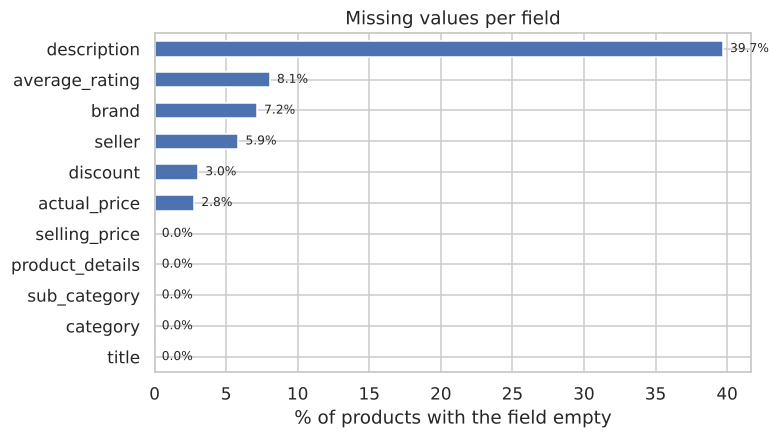

In [13]:
fields = ["title", "description", "brand", "seller", "category", "sub_category",
          "actual_price", "selling_price", "discount", "average_rating", "product_details"]
missing = pd.Series({f: (raw_df[f].apply(lambda v: v in (None, "", [], {}))).mean() * 100 for f in fields}).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
missing.plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("% of products with the field empty")
ax.set_title("Missing values per field")
for i, v in enumerate(missing):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
save(fig, "missing_values"); plt.show()

### 3.2 Length of the texts (word counts and sentence length)

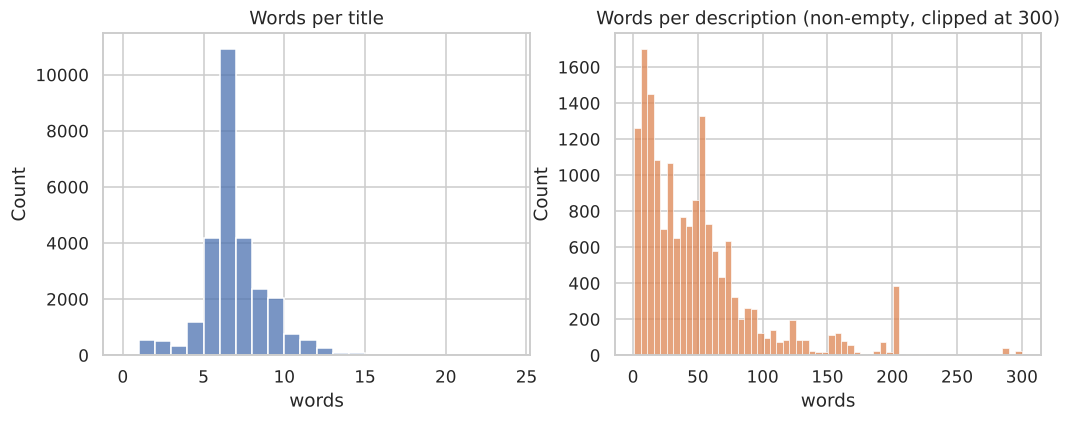

               count  mean  std  min  25%  50%  75%   max
title_words  28080.0   6.5  2.1  1.0  6.0  6.0  7.0  35.0
              count  mean   std  min   25%   50%   75%    max
desc_words  16930.0  49.4  47.8  1.0  14.0  39.0  63.0  621.0


In [14]:
raw_df["title_words"] = raw_df["title"].apply(lambda t: len(remove_punctuation(tokenize(normalize_text(t)))))
raw_df["desc_words"] = raw_df["description"].apply(lambda t: len(remove_punctuation(tokenize(normalize_text(t)))))
has_desc = raw_df["desc_words"] > 0

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(raw_df["title_words"], bins=range(0, 25), ax=axes[0], color="#4C72B0")
axes[0].set_title("Words per title"); axes[0].set_xlabel("words")
sns.histplot(raw_df.loc[has_desc, "desc_words"].clip(upper=300), bins=60, ax=axes[1], color="#DD8452")
axes[1].set_title("Words per description (non-empty, clipped at 300)"); axes[1].set_xlabel("words")
save(fig, "word_counts"); plt.show()

print(raw_df[["title_words"]].describe().T.round(1))
print(raw_df.loc[has_desc, ["desc_words"]].describe().T.round(1))

In [15]:
# Average sentence length in descriptions (sentences split on . ! ?)
sent_lens = []
for d in raw_df.loc[has_desc, "description"]:
    for s in re.split(r"[.!?]+", d):
        n = len(remove_punctuation(tokenize(normalize_text(s))))
        if n:
            sent_lens.append(n)
print(f"Sentences: {len(sent_lens):,} | mean length {np.mean(sent_lens):.1f} words | median {np.median(sent_lens):.0f}")

Sentences: 56,500 | mean length 14.8 words | median 14


### 3.3 Vocabulary size and the effect of each pre-processing step

In [16]:
text = (raw_df["title"] + " " + raw_df["description"].fillna("")).tolist()
tok_lists = [remove_punctuation(tokenize(normalize_text(t))) for t in text]
v_raw = {w for toks in tok_lists for w in toks}
v_nostop = {w for toks in tok_lists for w in toks if w not in STOP_WORDS and not w.isdigit() and len(w) > 1}
v_stem = {w for t in text for w in build_terms(t)}
tokens_raw = sum(len(t) for t in tok_lists)
tokens_final = int(sum(len(build_terms(t)) for t in text))
vocab = pd.DataFrame({"vocabulary size": [len(v_raw), len(v_nostop), len(v_stem)]},
                     index=["tokens (lower-case, no punctuation)", "+ stop words / numbers removed", "+ stemming"])
print(f"Total tokens: {tokens_raw:,} -> {tokens_final:,} after pre-processing ({100*(1-tokens_final/tokens_raw):.0f}% fewer)")
vocab

Total tokens: 1,017,534 -> 684,495 after pre-processing (33% fewer)


,vocabulary size
"tokens (lower-case, no punctuation)",6968
+ stop words / numbers removed,6663
+ stemming,5154


### 3.4 Most frequent terms and word clouds

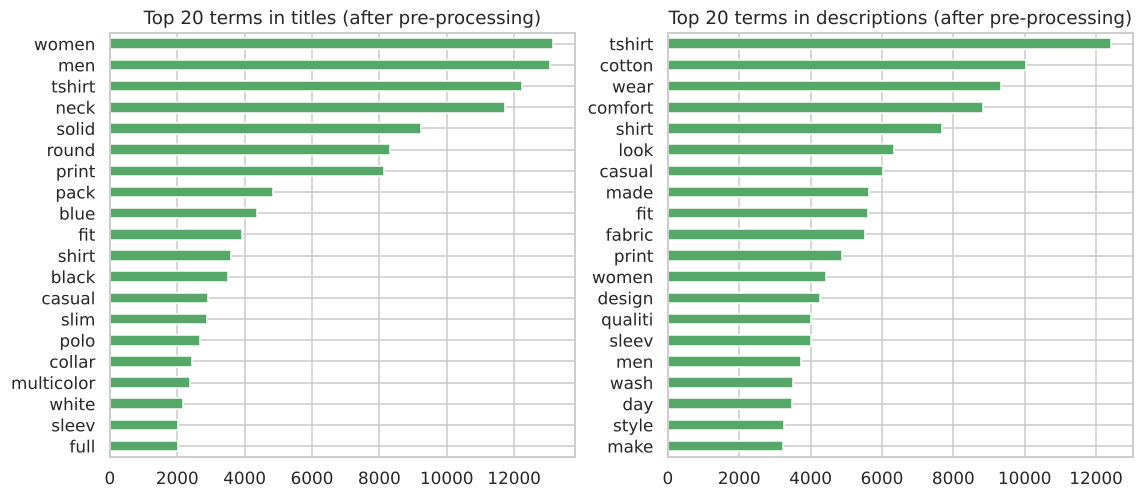

In [17]:
title_freq = collections.Counter(t for ts in corpus["title_terms"] for t in ts)
desc_freq = collections.Counter(t for ts in corpus["description_terms"] for t in ts)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, freq, name in [(axes[0], title_freq, "titles"), (axes[1], desc_freq, "descriptions")]:
    top = pd.Series(dict(freq.most_common(20)))[::-1]
    top.plot.barh(ax=ax, color="#55A868")
    ax.set_title(f"Top 20 terms in {name} (after pre-processing)")
save(fig, "top_terms"); plt.show()

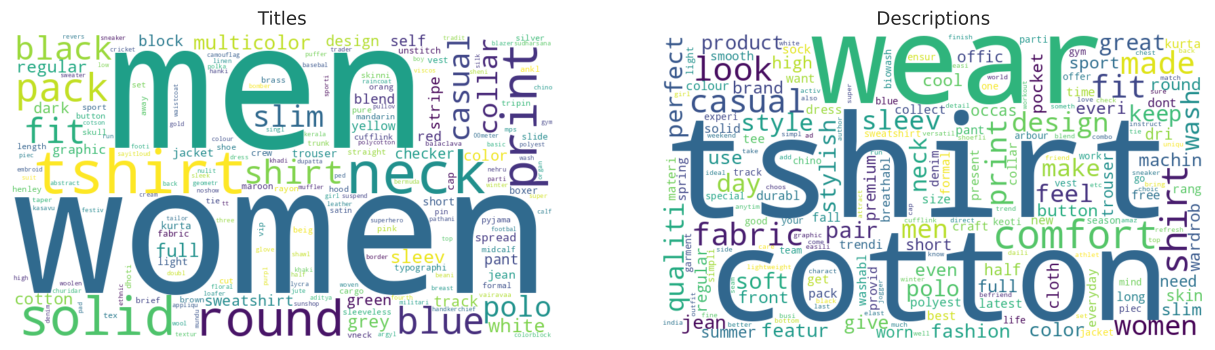

In [18]:
try:
    from wordcloud import WordCloud
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, freq, name in [(axes[0], title_freq, "Titles"), (axes[1], desc_freq, "Descriptions")]:
        wc = WordCloud(width=800, height=450, background_color="white", colormap="viridis").generate_from_frequencies(freq)
        ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(name)
    save(fig, "wordclouds"); plt.show()
except ImportError:
    print("Install `wordcloud` (pip install wordcloud) to draw the word clouds.")

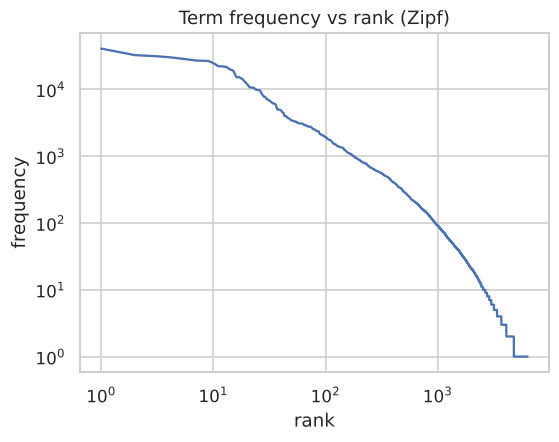

Terms appearing only once: 1,547 of 6,304 (25%)


In [19]:
# Zipf's law check: rank vs frequency on log-log axes (all fields together)
all_freq = collections.Counter(t for ts in corpus["all_terms"] for t in ts)
f = np.array(sorted(all_freq.values(), reverse=True))
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(np.arange(1, len(f) + 1), f, color="#4C72B0")
ax.set_xlabel("rank"); ax.set_ylabel("frequency"); ax.set_title("Term frequency vs rank (Zipf)")
save(fig, "zipf"); plt.show()
print(f"Terms appearing only once: {(f == 1).sum():,} of {len(f):,} ({100*(f==1).mean():.0f}%)")

### 3.5 Categories and sub-categories

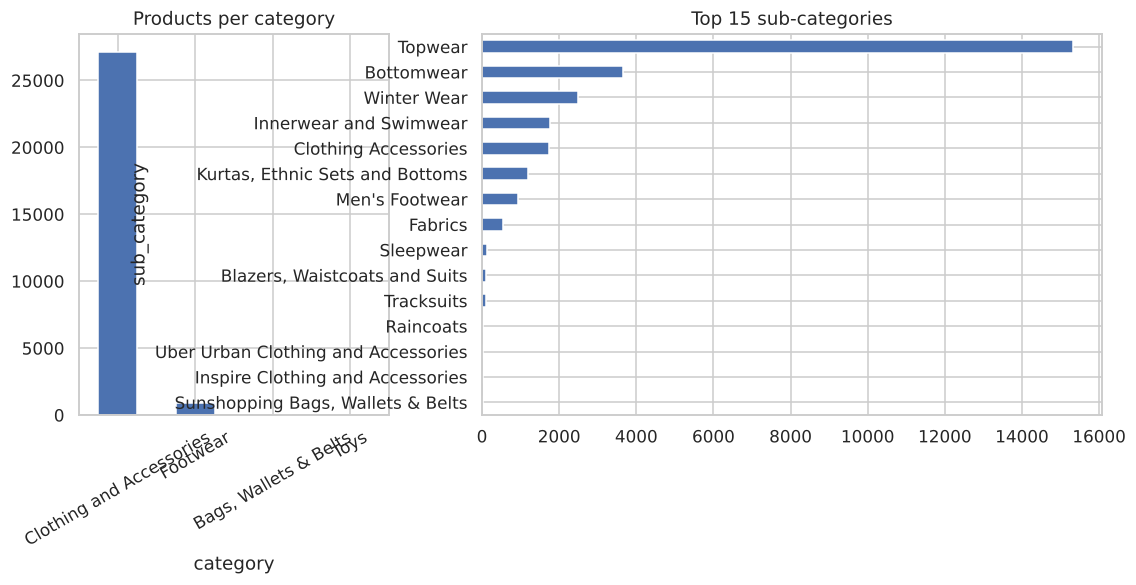

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 2]})
raw_df["category"].value_counts().plot.bar(ax=axes[0], color="#4C72B0"); axes[0].set_title("Products per category")
raw_df["sub_category"].value_counts().head(15)[::-1].plot.barh(ax=axes[1], color="#4C72B0"); axes[1].set_title("Top 15 sub-categories")
axes[0].tick_params(axis="x", rotation=30)
save(fig, "categories"); plt.show()

### 3.6 Top brands and sellers

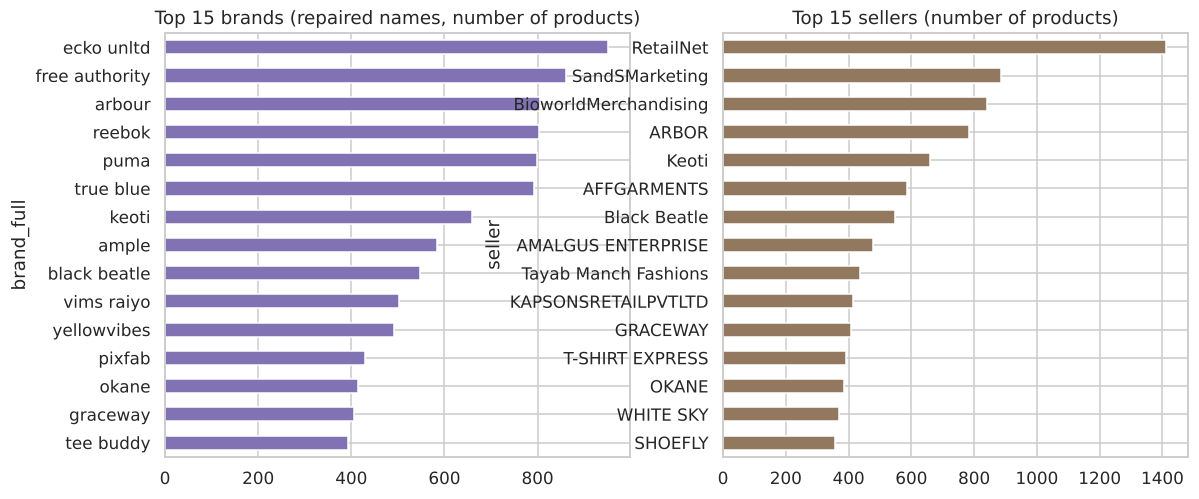

Top-10 brands hold 28% of the products


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
raw_df.loc[raw_df["brand"] != "", "brand_full"].value_counts().head(15)[::-1].plot.barh(ax=axes[0], color="#8172B3")
axes[0].set_title("Top 15 brands (repaired names, number of products)")
raw_df.loc[raw_df["seller"] != "", "seller"].value_counts().head(15)[::-1].plot.barh(ax=axes[1], color="#937860")
axes[1].set_title("Top 15 sellers (number of products)")
save(fig, "brands_sellers"); plt.show()
share = raw_df.loc[raw_df["brand"] != "", "brand_full"].value_counts(normalize=True).head(10).sum()
print(f"Top-10 brands hold {100*share:.0f}% of the products")

### 3.7 Stock availability

out_of_stock
in stock        26436
out of stock     1644
Name: count, dtype: int64 
5.9% out of stock


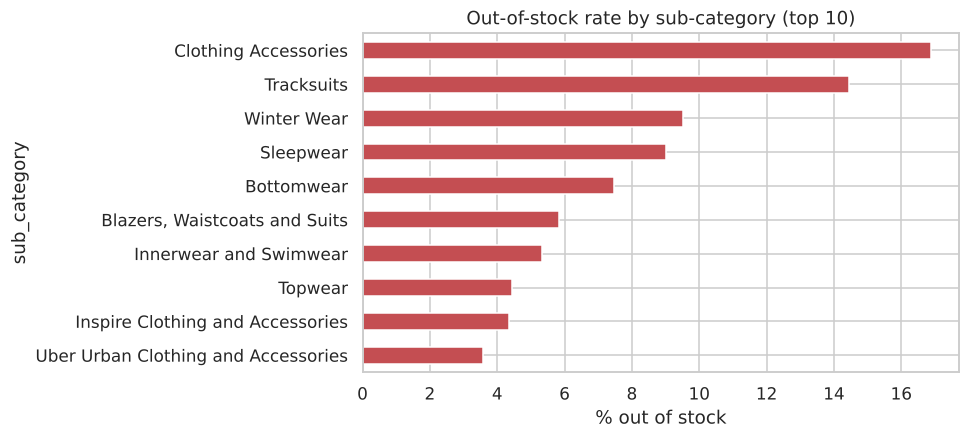

In [22]:
oos = corpus["out_of_stock"].value_counts().rename({False: "in stock", True: "out of stock"})
print(oos, f"\n{100*corpus['out_of_stock'].mean():.1f}% out of stock")
by_sub = corpus.groupby("sub_category")["out_of_stock"].mean().sort_values(ascending=False).head(10) * 100
fig, ax = plt.subplots(figsize=(7, 4))
by_sub[::-1].plot.barh(ax=ax, color="#C44E52"); ax.set_xlabel("% out of stock"); ax.set_title("Out-of-stock rate by sub-category (top 10)")
save(fig, "out_of_stock"); plt.show()

### 3.8 Prices, discounts and ratings

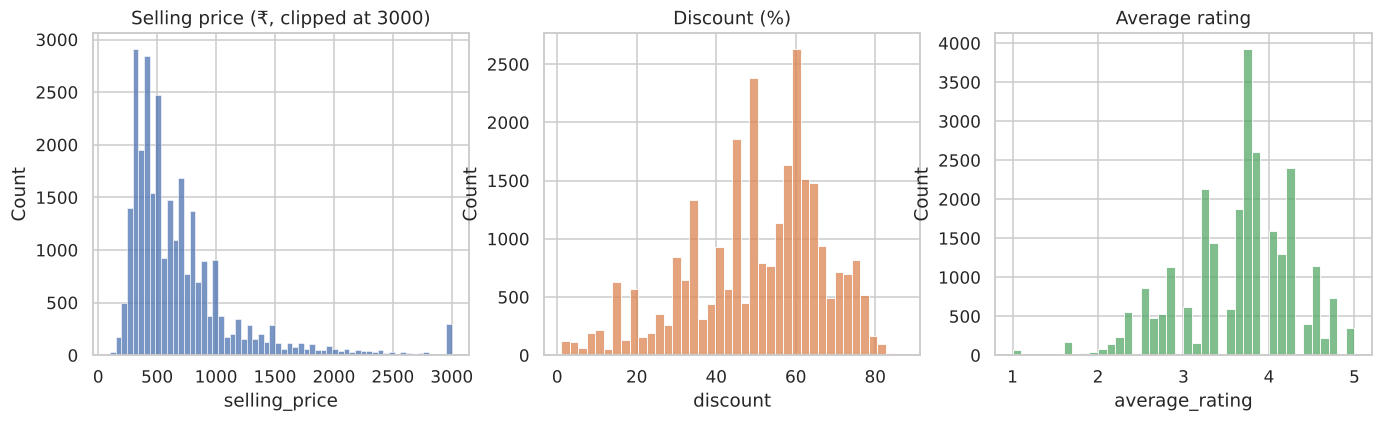

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(corpus["selling_price"].dropna().clip(upper=3000), bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("Selling price (₹, clipped at 3000)")
sns.histplot(corpus["discount"].dropna(), bins=40, ax=axes[1], color="#DD8452"); axes[1].set_title("Discount (%)")
sns.histplot(corpus["average_rating"].dropna(), bins=40, ax=axes[2], color="#55A868"); axes[2].set_title("Average rating")
save(fig, "price_discount_rating"); plt.show()

In [24]:
cols = ["title", "brand_full", "selling_price", "discount", "average_rating"]
print("Top 10 by rating (ties broken by bigger discount):")
display(corpus.sort_values(["average_rating", "discount"], ascending=False)[cols].head(10))
print("Top 10 by discount:")
display(corpus.sort_values("discount", ascending=False)[cols].head(10))
print("Top 10 most expensive:")
display(corpus.sort_values("selling_price", ascending=False)[cols].head(10))

Top 10 by rating (ties broken by bigger discount):


,title,brand_full,selling_price,discount,average_rating
pid,,,,,
KTAFAKGUKA2SXSEQ,Men Solid Cotton Blend Pathani Kurta (Blue),purple state,449.0,82.0,5.0
BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),sayitloud,249.0,78.0,5.0
TSHFNJ9ZEUZG3CPU,Printed Women Round Neck Multicolor T-Shirt,yellowvibes,275.0,77.0,5.0
TSHFU5AF8KZC5FYH,Printed Women Round Neck Black T-Shirt,pixfab,289.0,77.0,5.0
TSHFTT2JATXKUHEV,Solid Women Round Neck Black T-Shirt,pixfab,288.0,77.0,5.0
TSHFSPXRXEFVFTXG,Solid Women Round Neck Dark Blue T-Shirt,pixfab,288.0,77.0,5.0
TSHFTT2STQWNBH23,Printed Men Round Neck Blue T-Shirt,pixfab,288.0,77.0,5.0
TSHFTT2JUVYZFJZY,Solid Women Round Neck Yellow T-Shirt,pixfab,288.0,77.0,5.0
TSHFTT2SFXUT3N7F,Printed Women Round Neck Yellow T-Shirt,pixfab,288.0,77.0,5.0


Top 10 by discount:


,title,brand_full,selling_price,discount,average_rating
pid,,,,,
TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,jack royal,128.0,87.0,3.0
TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,jack royal,136.0,86.0,4.1
TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,jack royal,136.0,86.0,4.7
TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pa...,yellowvibes,449.0,85.0,3.2
TSHEYQ73AFZZ4QHX,"Printed Women Round or Crew Black, Grey T-Shirt",fairdeals,201.0,84.0,3.8
CTPFVZTBN4GRZKXH,nu-Lite Satin Tie & Cufflink (Red),,499.0,84.0,2.7
TSHFVM4PQPRY2CRZ,Color Block Women Round Neck Green T-Shirt,refro,228.0,84.0,4.2
TSHFGFNBYVKZBQ2M,Printed Men Collared Neck Multicolor T-Shirt,yellowvibes,230.0,84.0,4.6
TSHFKHRYJYMEMZHK,Printed Men Mandarin Collar Blue T-Shirt,yellowvibes,282.0,84.0,4.2


Top 10 most expensive:


,title,brand_full,selling_price,discount,average_rating
pid,,,,,
TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,reebok,7999.0,20.0,2.7
BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sle...,true blue,7998.0,NaN,2.6
JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,puma,7799.0,40.0,3.7
SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,puma,7799.0,40.0,4.5
JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,gas,7794.0,40.0,4.2
BZRFVDGUJHTQHDAX,Self Design Single Breasted Party Women Full S...,true blue,6998.0,NaN,2.6
JEAF8S4GE8PKH7H3,Regular Fit Men Dark Blue Cotton Blend Trousers,gas,6925.0,36.0,4.5
JEAF65G3MZYG3BQM,Maxx Regular Men Black Jeans,gas,6692.0,39.0,3.8
JCKFQF5K72AT2JDC,Full Sleeve Solid Women Casual Jacket,puma,6499.0,50.0,3.7


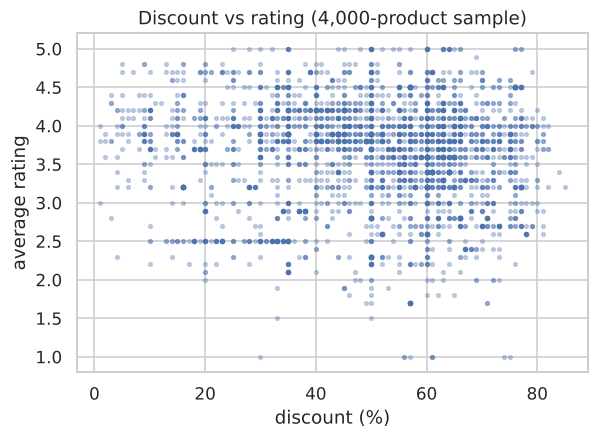

Spearman correlations:


,selling_price,actual_price,discount,average_rating
selling_price,1.00,0.77,-0.37,-0.03
actual_price,0.77,1.00,0.26,-0.09
discount,-0.37,0.26,1.00,-0.10
average_rating,-0.03,-0.09,-0.10,1.00


In [25]:
fig, ax = plt.subplots(figsize=(6, 4))
sample = corpus.dropna(subset=["discount", "average_rating"]).sample(4000, random_state=0)
ax.scatter(sample["discount"], sample["average_rating"], s=6, alpha=0.3)
ax.set_xlabel("discount (%)"); ax.set_ylabel("average rating"); ax.set_title("Discount vs rating (4,000-product sample)")
save(fig, "discount_vs_rating"); plt.show()
print("Spearman correlations:")
corpus[num_cols].corr(method="spearman").round(2)

### 3.9 Named-entity recognition

spaCy (`en_core_web_sm`) on a random sample of 2,000 non-empty descriptions.
Product descriptions are short marketing texts, so expect many brands tagged as ORG/PERSON and some errors.

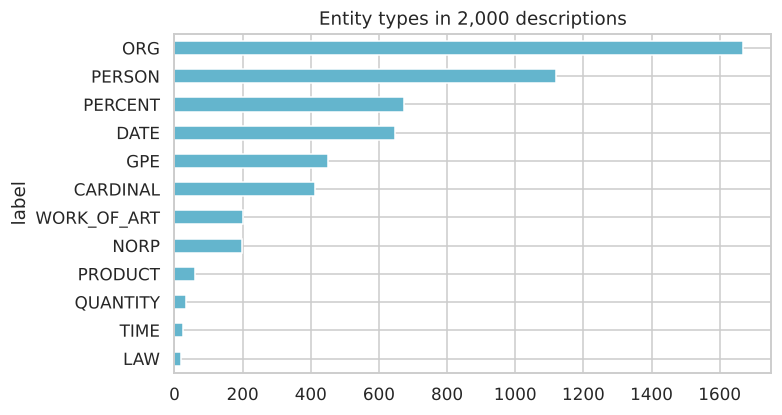

ORG      keoti (48), printed (45), round neck tees (34), tshirt (31), the amazing comfort of a shoefly polo t-shirts (27), the amazing comfort of a keoti polo t-shirts (26), half & full sleeve (23), xxl (22)
GPE      cotton (104), kurta (84), india (74), ladies (25), solid (21), ldhsati (16), sweatshirt (15), shoefly (11)
PERSON   casual wear (50), track pant (48), cotton (41), lucky bird (38), arbour (37), denims (36), cotton fabric (31), casual (27)
PRODUCT  round (16), everland (10), s-xxl (6), half sleeve t-shirt (5), shirt (3), micromodal (3), exclusive (2), classic black and (2)


In [26]:
try:
    import spacy
    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])
    sample_desc = raw_df.loc[has_desc, "description"].sample(2000, random_state=42).tolist()
    ents = [(e.text.strip(), e.label_) for doc in nlp.pipe(sample_desc, batch_size=200) for e in doc.ents]
    ent_df = pd.DataFrame(ents, columns=["entity", "label"])
    fig, ax = plt.subplots(figsize=(7, 4))
    ent_df["label"].value_counts().head(12)[::-1].plot.barh(ax=ax, color="#64B5CD")
    ax.set_title("Entity types in 2,000 descriptions")
    save(fig, "ner_labels"); plt.show()
    for lab in ["ORG", "GPE", "PERSON", "PRODUCT"]:
        top = ent_df.loc[ent_df["label"] == lab, "entity"].str.lower().value_counts().head(8)
        print(f"{lab:8}", ", ".join(f"{k} ({v})" for k, v in top.items()))
except (ImportError, OSError):
    print("spaCy model not available. Run: pip install spacy && python -m spacy download en_core_web_sm")

## 4. Save the processed corpus (input for Part 2)

In [27]:
out = DATA / "processed_corpus.pkl"
corpus.to_pickle(out)
print(f"Saved {len(corpus):,} processed products to {out}")
corpus[["pid", "title_terms", "details_terms", "brand_full", "brand_terms", "selling_price", "discount", "average_rating"]].head()

Saved 28,080 processed products to irwa-search-engine/data/processed_corpus.pkl


,pid,title_terms,details_terms,brand_full,brand_terms,selling_price,discount,average_rating
pid,,,,,,,,
TKPFCZ9EA7H5FYZH,TKPFCZ9EA7H5FYZH,"[solid, women, multicolor, track, pant]","[elast, side, pocket, cotton, blend, solid, mu...",yorker,[yorker],921.0,69.0,3.9
TKPFCZ9EJZV2UVRZ,TKPFCZ9EJZV2UVRZ,"[solid, men, blue, track, pant]","[drawstr, elast, side, pocket, cotton, blend, ...",yorker,[yorker],499.0,66.0,3.9
TKPFCZ9EHFCY5Z4Y,TKPFCZ9EHFCY5Z4Y,"[solid, men, multicolor, track, pant]","[elast, side, pocket, cotton, blend, solid, mu...",yorker,[yorker],931.0,68.0,3.9
TKPFCZ9ESZZ7YWEF,TKPFCZ9ESZZ7YWEF,"[solid, women, multicolor, track, pant]","[elast, side, pocket, cotton, blend, solid, mu...",yorker,[yorker],911.0,69.0,3.9
TKPFCZ9EVXKBSUD7,TKPFCZ9EVXKBSUD7,"[solid, women, brown, grey, track, pant]","[drawstr, elast, side, pocket, cotton, blend, ...",yorker,[yorker],943.0,68.0,3.9
